# minRNN — Foundations (minGRU / minLSTM)

Self-contained notebook for *Were RNNs All We Needed?* (Feng et al., 2024).

minGRU and minLSTM as the linear recurrence `h_t = a_t * h_{t-1} + b_t`,
computed three ways (sequential, parallel log-space, vanilla), plus a correctness harness.

GPU on Colab: **Runtime > Change runtime type > GPU**.


## 1. Environment

In [1]:
import torch

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device =", dev)
if dev == "cuda":
    print("gpu  =", torch.cuda.get_device_name(0))


torch 2.14.1+cu130 | device = cuda
gpu  = Tesla T4


## 2. Scan primitives

The shared recurrence engine every model reuses.

In [2]:
import torch.nn.functional as F


# g is the positive activation that replaces tanh; log_g is its log
def g(x):
    return torch.where(x >= 0, x + 0.5, torch.sigmoid(x))


def log_g(x):
    return torch.where(x >= 0, (F.relu(x) + 0.5).log(), -F.softplus(-x))


def heinsen_associative_scan_log(log_coeffs, log_values):
    a_star = log_coeffs.cumsum(dim=1)
    log_h0_plus_b_star = torch.logcumsumexp(log_values - a_star, dim=1)
    return (a_star + log_h0_plus_b_star).exp()


def naive_sequential_scan(a, b, h0=None):
    B, T, D = a.shape
    h_prev = torch.zeros(B, D, dtype=a.dtype, device=a.device) if h0 is None else h0
    outs = []
    for t in range(T):
        h_prev = a[:, t] * h_prev + b[:, t]
        outs.append(h_prev)
    return torch.stack(outs, dim=1)


def vanilla_scan(a, b, h0=None):
    A = torch.cumprod(a, dim=1)
    inner = torch.cumsum(b / A, dim=1)
    if h0 is not None:
        inner = inner + h0.unsqueeze(1)
    return A * inner


## 3. minGRU

Gates depend on the current input, not the previous hidden state, which is what makes it parallelizable.

In [3]:
import torch.nn as nn


def _scan_log_with_h0(log_a, log_b, h0=None):
    B, T, D = log_a.shape
    log_a = F.pad(log_a, (0, 0, 1, 0))
    if h0 is None:
        log_h0 = torch.full((B, 1, D), float("-inf"), dtype=log_b.dtype, device=log_b.device)
    else:
        log_h0 = h0.clamp(min=1e-20).log().unsqueeze(1)
    log_b = torch.cat([log_h0, log_b], dim=1)
    return heinsen_associative_scan_log(log_a, log_b)[:, 1:]


class minGRU(nn.Module):
    def __init__(self, dim, hidden_dim=None, proj_out=False):
        super().__init__()
        hidden_dim = hidden_dim or dim
        self.dim, self.hidden_dim = dim, hidden_dim
        self.to_z = nn.Linear(dim, hidden_dim, bias=False)
        self.to_h = nn.Linear(dim, hidden_dim, bias=False)
        self.to_out = nn.Linear(hidden_dim, dim, bias=False) if proj_out else nn.Identity()

    def _pre(self, x):
        return self.to_z(x), self.to_h(x)

    def forward_parallel_log(self, x, h0=None):
        pre_z, pre_h = self._pre(x)
        log_a = -F.softplus(pre_z)
        log_z = -F.softplus(-pre_z)
        log_b = log_z + log_g(pre_h)
        return self.to_out(_scan_log_with_h0(log_a, log_b, h0))

    def forward_parallel_vanilla(self, x, h0=None):
        pre_z, pre_h = self._pre(x)
        z = pre_z.sigmoid()
        return self.to_out(vanilla_scan(1.0 - z, z * g(pre_h), h0))

    def forward_sequential(self, x, h0=None):
        pre_z, pre_h = self._pre(x)
        z = pre_z.sigmoid()
        return self.to_out(naive_sequential_scan(1.0 - z, z * g(pre_h), h0))

    def forward(self, x, h0=None, mode="parallel_log"):
        return {"parallel_log": self.forward_parallel_log,
                "parallel_vanilla": self.forward_parallel_vanilla,
                "sequential": self.forward_sequential}[mode](x, h0)


## 4. minLSTM

Same structure; forget/input gates are normalized to sum to 1.

In [4]:
class minLSTM(nn.Module):
    def __init__(self, dim, hidden_dim=None, proj_out=False):
        super().__init__()
        hidden_dim = hidden_dim or dim
        self.dim, self.hidden_dim = dim, hidden_dim
        self.to_f = nn.Linear(dim, hidden_dim, bias=False)
        self.to_i = nn.Linear(dim, hidden_dim, bias=False)
        self.to_h = nn.Linear(dim, hidden_dim, bias=False)
        self.to_out = nn.Linear(hidden_dim, dim, bias=False) if proj_out else nn.Identity()

    def _pre(self, x):
        return self.to_f(x), self.to_i(x), self.to_h(x)

    def forward_parallel_log(self, x, h0=None):
        pre_f, pre_i, pre_h = self._pre(x)
        log_f = -F.softplus(-pre_f)
        log_i = -F.softplus(-pre_i)
        log_denom = torch.logaddexp(log_f, log_i)
        log_a = log_f - log_denom
        log_b = (log_i - log_denom) + log_g(pre_h)
        return self.to_out(_scan_log_with_h0(log_a, log_b, h0))

    def _ab(self, x):
        pre_f, pre_i, pre_h = self._pre(x)
        f, i = pre_f.sigmoid(), pre_i.sigmoid()
        denom = f + i
        return f / denom, (i / denom) * g(pre_h)

    def forward_parallel_vanilla(self, x, h0=None):
        a, b = self._ab(x)
        return self.to_out(vanilla_scan(a, b, h0))

    def forward_sequential(self, x, h0=None):
        a, b = self._ab(x)
        return self.to_out(naive_sequential_scan(a, b, h0))

    def forward(self, x, h0=None, mode="parallel_log"):
        return {"parallel_log": self.forward_parallel_log,
                "parallel_vanilla": self.forward_parallel_vanilla,
                "sequential": self.forward_sequential}[mode](x, h0)


## 5. Smoke test

In [5]:
torch.manual_seed(0)
B, T, D = 4, 64, 32
x = torch.randn(B, T, D, device=dev)

print(f"{'model':8s} {'shape':>16s} {'max|seq-log|':>14s} {'max|seq-vanilla|':>18s}")
for name, M in [("minGRU", minGRU(D)), ("minLSTM", minLSTM(D))]:
    M = M.to(dev)
    seq = M(x, mode="sequential")
    plog = M(x, mode="parallel_log")
    pvan = M(x, mode="parallel_vanilla")
    print(f"{name:8s} {str(tuple(plog.shape)):>16s} "
          f"{(seq-plog).abs().max().item():>14.2e} {(seq-pvan).abs().max().item():>18.2e}")

M = minGRU(D).to(dev)
M(x, mode="parallel_log").sum().backward()
print("grad norm (minGRU to_z):", f"{M.to_z.weight.grad.norm().item():.4f}")


model               shape   max|seq-log|   max|seq-vanilla|
minGRU        (4, 64, 32)       6.08e-06           2.38e-07
minLSTM       (4, 64, 32)       5.72e-06           2.38e-07
grad norm (minGRU to_z): 251.9081


## 6. Correctness harness (Foundation 2)

Float64 on CPU for tight tolerances.

In [6]:
import itertools

MODELS = [minGRU, minLSTM]
SHAPES = [(2, 16, 8), (3, 64, 32), (1, 128, 16)]


def _model(cls, dim, seed=0):
    torch.manual_seed(seed)
    return cls(dim).double()


def test_parallel_log_matches_sequential():
    for cls, (B, T, D) in itertools.product(MODELS, SHAPES):
        M = _model(cls, D)
        x = torch.randn(B, T, D, dtype=torch.float64)
        err = (M(x, mode="sequential") - M(x, mode="parallel_log")).abs().max().item()
        assert err < 1e-8, f"{cls.__name__} {(B,T,D)} err={err:.2e}"


def test_vanilla_matches_sequential_short():
    for cls in MODELS:
        M = _model(cls, 8)
        x = torch.randn(2, 16, 8, dtype=torch.float64)
        err = (M(x, mode="sequential") - M(x, mode="parallel_vanilla")).abs().max().item()
        assert err < 1e-8, f"{cls.__name__} vanilla err={err:.2e}"


def test_gradients_finite_and_nonzero():
    for cls in MODELS:
        M = _model(cls, 16)
        x = torch.randn(2, 32, 16, dtype=torch.float64)
        M(x, mode="parallel_log").sum().backward()
        for n, p in M.named_parameters():
            assert p.grad is not None and torch.isfinite(p.grad).all() and p.grad.abs().sum() > 0, n


def test_gradcheck():
    for cls in MODELS:
        M = _model(cls, 4)
        x = torch.randn(1, 8, 4, dtype=torch.float64, requires_grad=True)
        assert torch.autograd.gradcheck(lambda i: M(i, mode="parallel_log"), (x,), eps=1e-6, atol=1e-4)


def test_overfit_tiny():
    for cls in MODELS:
        torch.manual_seed(0)
        M = cls(8, hidden_dim=64, proj_out=True)
        x, y = torch.randn(1, 10, 8), torch.randn(1, 10, 8)
        opt = torch.optim.Adam(M.parameters(), lr=3e-3)
        loss0 = None
        for step in range(1500):
            opt.zero_grad()
            loss = ((M(x, mode="parallel_log") - y) ** 2).mean()
            loss.backward()
            opt.step()
            if step == 0:
                loss0 = loss.item()
        assert loss.item() < 0.05 * loss0, f"{cls.__name__} {loss0:.4f} -> {loss.item():.4f}"


tests = [v for k, v in sorted(globals().items()) if k.startswith("test_")]
failed = 0
for fn in tests:
    try:
        fn()
        print("PASS ", fn.__name__)
    except AssertionError as e:
        failed += 1
        print("FAIL ", fn.__name__, e)
print(f"\n{len(tests) - failed}/{len(tests)} passed")


PASS  test_gradcheck
PASS  test_gradients_finite_and_nonzero
PASS  test_overfit_tiny
PASS  test_parallel_log_matches_sequential
PASS  test_vanilla_matches_sequential_short

5/5 passed


## 7. Log-space vs vanilla stability

Vanilla underflows on long sequences; log-space stays accurate. Motivates variation 2.

In [7]:
torch.manual_seed(0)
M = minGRU(16).to(dev)
for Tlen in [256, 1024, 4096]:
    xx = torch.randn(1, Tlen, 16, device=dev)
    seq = M(xx, mode="sequential")
    log = M(xx, mode="parallel_log")
    van = M(xx, mode="parallel_vanilla")
    print(f"T={Tlen:5d}  max|seq-log|={(seq-log).abs().max().item():.2e}   "
          f"max|seq-vanilla|={(seq-van).abs().max().item():.2e}")


T=  256  max|seq-log|=2.11e-05   max|seq-vanilla|=nan
T= 1024  max|seq-log|=7.95e-05   max|seq-vanilla|=nan
T= 4096  max|seq-log|=4.25e-04   max|seq-vanilla|=nan


# Result 1: Efficiency benchmark

This section measures a complete forward pass, scalar loss, and backward pass as sequence length increases. It compares minGRU/minLSTM with plain-PyTorch GRU/LSTM cell recurrences and, when available, the official Mamba implementation.

Select **Runtime > Change runtime type > T4 GPU** in Colab. Run the environment, scan-primitives, minGRU, and minLSTM definition cells first (Sections 1–4), then run the cells in this Result 1 section. The intervening foundations demonstrations, correctness harness, and long-sequence stability comparison are optional and are not needed for this benchmark. The benchmark code is included here rather than imported from a helper script. A short configurable smoke run is available before the full sweep.

The paper specifies batch size 64, equal layer counts, forward/loss/backward measurement, and 100 timing runs. The hidden dimension and Mamba parameters below are explicit experiment settings and should be checked against the paper appendix before describing the experiment as an exact reproduction. GRU/LSTM use `GRUCell`/`LSTMCell` unrolled in Python to avoid fused sequence kernels.

## 8.1 Benchmark configuration

Use the smoke configuration first to verify the notebook and setup. Then restore the paper-style run settings. Keep the hardware and all settings fixed across models. The default sequence sweep includes the paper's cited lengths 512 and 4096.

In [8]:
from pathlib import Path
from datetime import datetime, timezone
import csv
import importlib.metadata
import statistics
import time
import sys

BENCHMARK = {
    "batch_size": 64,
    "dimension": 64,
    "layers": 1,
    "sequence_lengths": [256, 512, 1024, 2048, 4096],
    "warmup_iterations": 10,
    "measured_iterations": 100,
    "seed": 0,
    "dtype": torch.float32,
    "include_mamba": True,
}

SMOKE_TEST = False
if SMOKE_TEST:
    BENCHMARK.update({
        "batch_size": 2,
        "dimension": 8,
        "layers": 1,
        "sequence_lengths": [16, 32],
        "warmup_iterations": 1,
        "measured_iterations": 3,
        "include_mamba": False,
    })

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type != "cuda":
    print("WARNING: CUDA is unavailable. Runtime results will be CPU-only and GPU memory will not be measured.")

try:
    from mamba_ssm import Mamba
    mamba_import_error = None
except (ImportError, OSError) as error:
    Mamba = None
    mamba_import_error = str(error)

try:
    mamba_version = importlib.metadata.version("mamba-ssm")
except importlib.metadata.PackageNotFoundError:
    mamba_version = "not installed"

run_timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)
results_path = results_dir / f"result1_efficiency_{run_timestamp}.csv"
gpu_name = torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU"

print(f"PyTorch: {torch.__version__} | Python: {sys.version.split()[0]}")
print(f"Device: {device} | GPU: {gpu_name} | CUDA: {torch.version.cuda}")
print(f"Mamba package: {mamba_version}")
print("Configuration:", BENCHMARK)
print("CSV output:", results_path)

PyTorch: 2.14.1+cu130 | Python: 3.13.16
Device: cuda | GPU: Tesla T4 | CUDA: 13.0
Mamba package: not installed
Configuration: {'batch_size': 64, 'dimension': 64, 'layers': 1, 'sequence_lengths': [256, 512, 1024, 2048, 4096], 'warmup_iterations': 10, 'measured_iterations': 100, 'seed': 0, 'dtype': torch.float32, 'include_mamba': True}
CSV output: results/result1_efficiency_20261107_171150.csv


## 8.2 Baseline model implementations

The minRNN layers are defined earlier in this notebook. The traditional baselines below explicitly apply a PyTorch cell at every timestep, matching the paper's plain-PyTorch comparison rather than using fused `nn.GRU` or `nn.LSTM` sequence kernels. All models return a sequence with shape `(batch, time, dimension)`.

In [9]:
class GRUCellStack(nn.Module):
    def __init__(self, dimension, layers):
        super().__init__()
        self.cells = nn.ModuleList([
            nn.GRUCell(dimension, dimension) for _ in range(layers)
        ])

    def forward(self, inputs):
        batch_size, sequence_length, _ = inputs.shape
        values = inputs
        for cell in self.cells:
            hidden = values.new_zeros(batch_size, cell.hidden_size)
            outputs = []
            for step in range(sequence_length):
                hidden = cell(values[:, step], hidden)
                outputs.append(hidden)
            values = torch.stack(outputs, dim=1)
        return values


class LSTMCellStack(nn.Module):
    def __init__(self, dimension, layers):
        super().__init__()
        self.cells = nn.ModuleList([
            nn.LSTMCell(dimension, dimension) for _ in range(layers)
        ])

    def forward(self, inputs):
        batch_size, sequence_length, _ = inputs.shape
        values = inputs
        for cell in self.cells:
            hidden = values.new_zeros(batch_size, cell.hidden_size)
            cell_state = values.new_zeros(batch_size, cell.hidden_size)
            outputs = []
            for step in range(sequence_length):
                hidden, cell_state = cell(values[:, step], (hidden, cell_state))
                outputs.append(hidden)
            values = torch.stack(outputs, dim=1)
        return values


def build_benchmark_model(name, dimension, layers):
    if name == "minGRU":
        return nn.Sequential(*[minGRU(dimension) for _ in range(layers)]), "minGRU, parallel log-space scan"
    if name == "minLSTM":
        return nn.Sequential(*[minLSTM(dimension) for _ in range(layers)]), "minLSTM, parallel log-space scan"
    if name == "GRU":
        return GRUCellStack(dimension, layers), "torch.nn.GRUCell unrolled over time"
    if name == "LSTM":
        return LSTMCellStack(dimension, layers), "torch.nn.LSTMCell unrolled over time"
    if name == "Mamba":
        if Mamba is None:
            raise RuntimeError(f"Mamba is unavailable: {mamba_import_error}")
        return nn.Sequential(*[
            Mamba(d_model=dimension, d_state=16, d_conv=4, expand=2)
            for _ in range(layers)
        ]), "official mamba_ssm.Mamba (d_state=16, d_conv=4, expand=2)"
    raise ValueError(f"Unknown model: {name}")


model_names = ["minGRU", "minLSTM", "GRU", "LSTM"]
if BENCHMARK["include_mamba"]:
    model_names.append("Mamba")

print("Models:", model_names)

Models: ['minGRU', 'minLSTM', 'GRU', 'LSTM', 'Mamba']


## 8.3 Correctness preflight

Before timing, check output shape/finiteness and verify that the minGRU/minLSTM log-space scan agrees with the sequential recurrence on a short sequence. This catches implementation or setup mistakes before the more expensive sweep.

In [10]:
torch.manual_seed(BENCHMARK["seed"])
test_input = torch.randn(2, 16, 8, device=device, dtype=torch.float64)
for cell_type in (minGRU, minLSTM):
    layer = cell_type(8).double().to(device)
    with torch.no_grad():
        parallel = layer(test_input, mode="parallel_log")
        sequential = layer(test_input, mode="sequential")
    error = (parallel - sequential).abs().max().item()
    assert parallel.shape == test_input.shape
    assert torch.isfinite(parallel).all()
    assert error < 1e-8, f"{cell_type.__name__} scan error {error:.3e}"
    print(f"{cell_type.__name__}: output shape {tuple(parallel.shape)}, max scan error {error:.3e}")

for name in model_names:
    if name == "Mamba" and (Mamba is None or device.type != "cuda"):
        print("Mamba will be marked unavailable:", mamba_import_error or "a compatible CUDA device is required")
        continue
    model, _ = build_benchmark_model(name, 8, 1)
    model = model.to(device=device, dtype=torch.float32)
    with torch.no_grad():
        output = model(torch.randn(2, 16, 8, device=device))
    assert output.shape == (2, 16, 8), f"{name} output shape {tuple(output.shape)}"
    assert torch.isfinite(output).all(), f"{name} produced non-finite output"
print("Correctness preflight passed.")

minGRU: output shape (2, 16, 8), max scan error 1.332e-15
minLSTM: output shape (2, 16, 8), max scan error 2.442e-15
Mamba will be marked unavailable: No module named 'mamba_ssm'
Correctness preflight passed.


## 8.4 Timing and memory measurement

Each iteration computes the model output, a scalar mean-square loss, and gradients. CUDA is synchronized around the timed interval so asynchronous kernel launches are included in wall-clock step time. Peak allocated memory is recorded both as the total peak and as the increase above the already-allocated model and input. This is allocated memory, not total device reservation by the caching allocator.

In [11]:
CSV_FIELDS = [
    "timestamp_utc", "model", "implementation", "status", "device", "gpu_name",
    "python_version", "torch_version", "cuda_version", "mamba_ssm_version",
    "batch_size", "sequence_length", "dimension", "layers", "dtype",
    "warmup_iterations", "measured_iterations", "mean_step_seconds",
    "median_step_seconds", "std_step_seconds", "tokens_per_second",
    "peak_allocated_bytes", "baseline_allocated_bytes", "peak_incremental_bytes",
    "memory_metric", "speedup_vs_gru", "speedup_vs_lstm", "error",
]


def synchronize_device():
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def measure_model(name, model, inputs):
    model.train()
    batch_size, sequence_length, _ = inputs.shape

    with torch.no_grad():
        check_output = model(inputs)
        if check_output.shape != inputs.shape or not torch.isfinite(check_output).all():
            raise RuntimeError(f"{name} failed output shape/finiteness check")
    del check_output

    def forward_loss_backward():
        output = model(inputs)
        loss = output.square().mean()
        loss.backward()
        return loss

    for _ in range(BENCHMARK["warmup_iterations"]):
        model.zero_grad(set_to_none=True)
        forward_loss_backward()
    model.zero_grad(set_to_none=True)
    synchronize_device()

    if device.type == "cuda":
        baseline_allocated = torch.cuda.memory_allocated(device)
        torch.cuda.reset_peak_memory_stats(device)
    else:
        baseline_allocated = None

    durations = []
    for _ in range(BENCHMARK["measured_iterations"]):
        model.zero_grad(set_to_none=True)
        synchronize_device()
        start = time.perf_counter()
        loss = forward_loss_backward()
        synchronize_device()
        durations.append(time.perf_counter() - start)
        if not torch.isfinite(loss):
            raise RuntimeError(f"{name} produced a non-finite loss")
        del loss

    if device.type == "cuda":
        peak_allocated = torch.cuda.max_memory_allocated(device)
        peak_incremental = max(0, peak_allocated - baseline_allocated)
        memory_metric = "CUDA peak allocated bytes"
    else:
        peak_allocated = None
        peak_incremental = None
        memory_metric = "unavailable on CPU"

    mean_seconds = statistics.mean(durations)
    return {
        "status": "ok",
        "mean_step_seconds": mean_seconds,
        "median_step_seconds": statistics.median(durations),
        "std_step_seconds": statistics.stdev(durations) if len(durations) > 1 else 0.0,
        "tokens_per_second": batch_size * sequence_length / mean_seconds,
        "peak_allocated_bytes": peak_allocated,
        "baseline_allocated_bytes": baseline_allocated,
        "peak_incremental_bytes": peak_incremental,
        "memory_metric": memory_metric,
        "error": "",
    }


def result_row(name, implementation, sequence_length, **measurements):
    return {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "model": name,
        "implementation": implementation,
        "device": str(device),
        "gpu_name": gpu_name,
        "python_version": sys.version.split()[0],
        "torch_version": torch.__version__,
        "cuda_version": torch.version.cuda or "",
        "mamba_ssm_version": mamba_version,
        "batch_size": BENCHMARK["batch_size"],
        "sequence_length": sequence_length,
        "dimension": BENCHMARK["dimension"],
        "layers": BENCHMARK["layers"],
        "dtype": str(BENCHMARK["dtype"]).replace("torch.", ""),
        "warmup_iterations": BENCHMARK["warmup_iterations"],
        "measured_iterations": BENCHMARK["measured_iterations"],
        "speedup_vs_gru": "",
        "speedup_vs_lstm": "",
        **measurements,
    }


def save_results(rows):
    with results_path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=CSV_FIELDS)
        writer.writeheader()
        writer.writerows(rows)


print("Measurement functions ready.")

Measurement functions ready.


## 8.5 Run the sequence-length sweep

The notebook writes the CSV after every model/length pair. If a configuration runs out of CUDA memory, it is recorded and the remaining models continue. Other errors are allowed to surface instead of being silently hidden. The first run can take a while, especially for sequential cell baselines at long sequence lengths.

In [12]:
benchmark_rows = []
torch.manual_seed(BENCHMARK["seed"])

for sequence_length in BENCHMARK["sequence_lengths"]:
    input_generator = torch.Generator(device=device)
    input_generator.manual_seed(BENCHMARK["seed"] + sequence_length)
    inputs = torch.randn(
        BENCHMARK["batch_size"], sequence_length, BENCHMARK["dimension"],
        device=device, dtype=BENCHMARK["dtype"], generator=input_generator,
    )

    for name in model_names:
        if name == "Mamba" and (Mamba is None or device.type != "cuda"):
            reason = mamba_import_error or "Mamba benchmark requires a compatible CUDA device"
            row = result_row(name, "official mamba_ssm.Mamba", sequence_length,
                             status="unavailable", error=reason)
            benchmark_rows.append(row)
            save_results(benchmark_rows)
            print(f"{name:7} T={sequence_length:5} unavailable: {reason}")
            continue

        implementation = name
        try:
            torch.manual_seed(BENCHMARK["seed"])
            model, implementation = build_benchmark_model(
                name, BENCHMARK["dimension"], BENCHMARK["layers"]
            )
            model = model.to(device=device, dtype=BENCHMARK["dtype"])
            measurements = measure_model(name, model, inputs)
            row = result_row(name, implementation, sequence_length, **measurements)
        except torch.cuda.OutOfMemoryError as error:
            torch.cuda.empty_cache()
            row = result_row(
                name, implementation, sequence_length,
                status="out_of_memory", error=str(error).splitlines()[0],
            )

        benchmark_rows.append(row)
        save_results(benchmark_rows)
        if row["status"] == "ok":
            memory = row["peak_allocated_bytes"]
            memory_text = (
                f"{memory / 1024**2:.1f} MiB total, "
                f"{row['peak_incremental_bytes'] / 1024**2:.1f} MiB incremental"
                if memory is not None else "GPU memory unavailable"
            )
            print(
                f"{name:7} T={sequence_length:5} "
                f"mean={row['mean_step_seconds'] * 1000:.3f} ms "
                f"median={row['median_step_seconds'] * 1000:.3f} ms | {memory_text}"
            )
        else:
            print(f"{name:7} T={sequence_length:5} {row['status']}: {row['error']}")

print(f"\nSaved {len(benchmark_rows)} rows to {results_path}")

minGRU  T=  256 mean=3.847 ms median=3.642 ms | 97.9 MiB total, 69.2 MiB incremental
minLSTM T=  256 mean=4.459 ms median=4.429 ms | 109.8 MiB total, 81.1 MiB incremental
GRU     T=  256 mean=76.323 ms median=75.585 ms | 96.8 MiB total, 68.0 MiB incremental
LSTM    T=  256 mean=87.476 ms median=75.314 ms | 104.8 MiB total, 76.0 MiB incremental
Mamba   T=  256 unavailable: No module named 'mamba_ssm'
minGRU  T=  512 mean=7.210 ms median=7.009 ms | 170.9 MiB total, 138.2 MiB incremental
minLSTM T=  512 mean=8.750 ms median=8.747 ms | 194.8 MiB total, 162.1 MiB incremental
GRU     T=  512 mean=166.055 ms median=151.356 ms | 168.8 MiB total, 136.0 MiB incremental
LSTM    T=  512 mean=156.333 ms median=147.389 ms | 184.8 MiB total, 152.0 MiB incremental
Mamba   T=  512 unavailable: No module named 'mamba_ssm'
minGRU  T= 1024 mean=13.752 ms median=13.747 ms | 316.9 MiB total, 276.2 MiB incremental
minLSTM T= 1024 mean=17.163 ms median=17.161 ms | 364.8 MiB total, 324.1 MiB incremental
GRU   

## 8.6 Speedups and plots

Speedup is baseline runtime divided by the selected model's runtime at the same sequence length. Values above 1 mean the compared model was faster in this run. Memory uses incremental peak allocated bytes above model/input allocations. Save or download both the CSV and plots when sharing results.

,model,sequence_length,status,mean_step_seconds,median_step_seconds,peak_incremental_bytes,speedup_vs_gru,speedup_vs_lstm,error
0,minGRU,256,ok,0.003847,0.003642,7.254989e+07,19.838407,22.737246,
1,minLSTM,256,ok,0.004459,0.004429,8.506573e+07,17.116718,19.617857,
2,GRU,256,ok,0.076323,0.075585,7.130419e+07,NaN,1.146123,
3,LSTM,256,ok,0.087476,0.075314,7.970918e+07,0.872507,NaN,
4,Mamba,256,unavailable,NaN,NaN,NaN,NaN,NaN,No module named 'mamba_ssm'
5,minGRU,512,ok,0.007210,0.007009,1.449016e+08,23.030273,21.681906,
6,minLSTM,512,ok,0.008750,0.008747,1.700004e+08,18.977155,17.866088,
7,GRU,512,ok,0.166055,0.151356,1.426074e+08,NaN,0.941452,
8,LSTM,512,ok,0.156333,0.147389,1.594010e+08,1.062189,NaN,
9,Mamba,512,unavailable,NaN,NaN,NaN,NaN,NaN,No module named 'mamba_ssm'


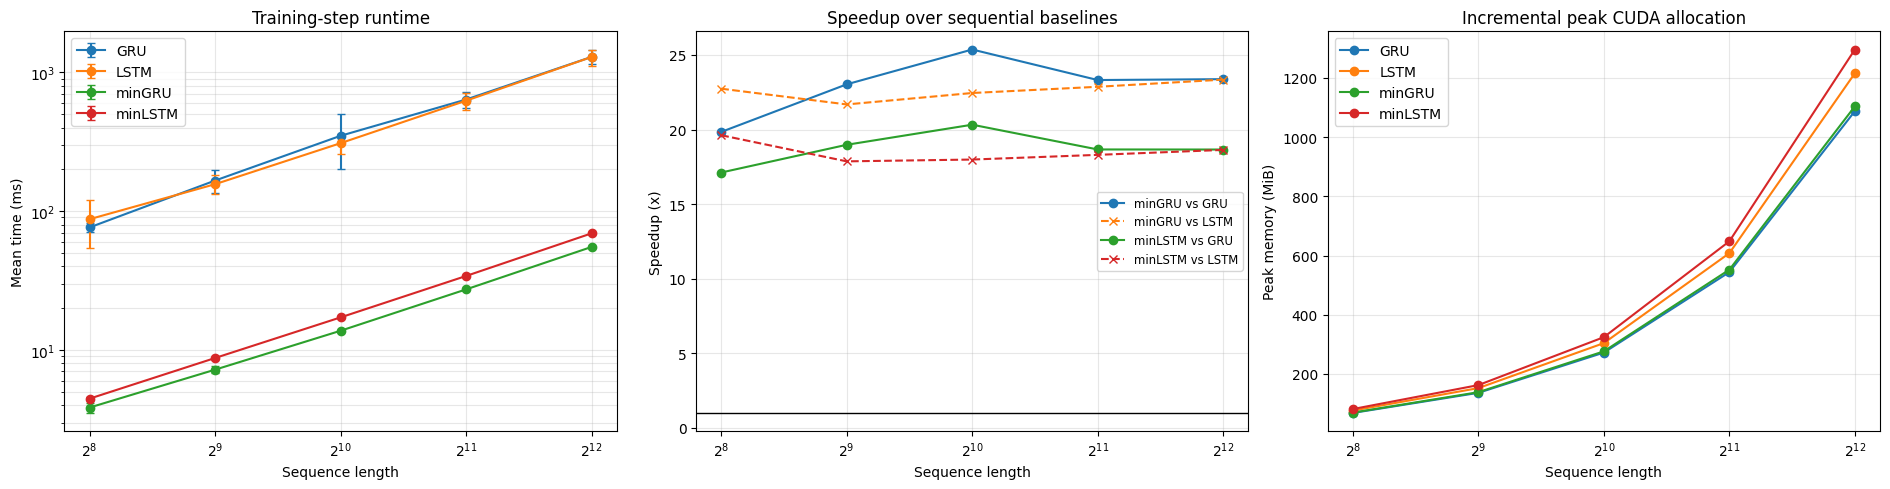

CSV: results/result1_efficiency_20261107_171150.csv
Plot: results/result1_efficiency_20261107_171150.png


In [13]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame(benchmark_rows)
successful = results[results["status"] == "ok"].copy()

for baseline in ("GRU", "LSTM"):
    baseline_times = successful[successful["model"] == baseline].set_index("sequence_length")["mean_step_seconds"]
    results[f"speedup_vs_{baseline.lower()}"] = results.apply(
        lambda row: (
            baseline_times.get(row["sequence_length"], float("nan")) / row["mean_step_seconds"]
            if row["status"] == "ok" and row["model"] != baseline
            and row["sequence_length"] in baseline_times.index else float("nan")
        ),
        axis=1,
    )

results.to_csv(results_path, index=False)
display(results[["model", "sequence_length", "status", "mean_step_seconds",
                 "median_step_seconds", "peak_incremental_bytes",
                 "speedup_vs_gru", "speedup_vs_lstm", "error"]])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
memory_plotted = False
for name, group in successful.groupby("model"):
    group = group.sort_values("sequence_length")
    axes[0].errorbar(group["sequence_length"], group["mean_step_seconds"] * 1000,
                     yerr=group["std_step_seconds"] * 1000,
                     marker="o", capsize=3, label=name)
    if group["peak_incremental_bytes"].notna().any():
        axes[2].plot(group["sequence_length"], group["peak_incremental_bytes"] / 1024**2,
                     marker="o", label=name)
        memory_plotted = True
axes[0].set(title="Training-step runtime", xlabel="Sequence length", ylabel="Mean time (ms)")
axes[0].set_xscale("log", base=2)
axes[0].set_yscale("log")
axes[0].grid(True, which="both", alpha=0.3)
if not successful.empty:
    axes[0].legend()

for model_name in ("minGRU", "minLSTM", "Mamba"):
    group = results[(results["model"] == model_name) & (results["status"] == "ok")]
    if not group.empty:
        axes[1].plot(group["sequence_length"], group["speedup_vs_gru"],
                     marker="o", label=f"{model_name} vs GRU")
        axes[1].plot(group["sequence_length"], group["speedup_vs_lstm"],
                     marker="x", linestyle="--", label=f"{model_name} vs LSTM")
axes[1].axhline(1, color="black", linewidth=1)
axes[1].set(title="Speedup over sequential baselines", xlabel="Sequence length", ylabel="Speedup (x)")
axes[1].set_xscale("log", base=2)
axes[1].grid(True, which="both", alpha=0.3)
if axes[1].lines:
    axes[1].legend(fontsize="small")

axes[2].set(title="Incremental peak CUDA allocation", xlabel="Sequence length", ylabel="Peak memory (MiB)")
axes[2].set_xscale("log", base=2)
axes[2].grid(True, which="both", alpha=0.3)
if memory_plotted:
    axes[2].legend()
else:
    axes[2].text(0.5, 0.5, "GPU memory measurements unavailable",
                 ha="center", va="center", transform=axes[2].transAxes)
fig.tight_layout()
plot_path = results_path.with_suffix(".png")
fig.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("CSV:", results_path)
print("Plot:", plot_path)

## 8.7 Reporting notes

Include the GPU model, PyTorch/CUDA/Mamba versions, batch size, dimension, number of layers, dtype, warmup count, measured iteration count, and any out-of-memory or unavailable configurations alongside the figures. Do not compare CPU smoke-test numbers to the paper's GPU results. Mamba is a separate modern baseline; the speedup plot uses GRU/LSTM as the reference. For a final paper-faithful reproduction, confirm model dimensions and Mamba settings from the paper's appendix and retain the generated CSV as the source for reported plots.